# Exploratory Data Analysis (IBM AML Small_HI)

This notebook computes and presents exploratory data analysis tables and figures for the IBM AML `Small_HI` transaction dataset using helper routines from `report_assets.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import report_assets as ra
from IPython.display import display, Image, Markdown
print('Loaded report_assets successfully.')

Loaded report_assets successfully.


## 1. Dataset Overview

The table below shows the total transaction rows, distinct accounts, total duration in days, laundering transaction count, and overall dataset laundering prevalence in `formatted_transactions.csv`.

In [2]:
df_overview = ra.eda_overview_table()
display(df_overview)

,Metric,Value
0,Total Transactions (Rows),"5,078,345"
1,Distinct Accounts,"515,088"
2,Time Span (Days),18
3,Laundering Transactions,"5,177"
4,Laundering Prevalence Rate,0.001019 (0.1019%)


## 2. Daily Laundering Rate and Daily Volume Across Split Partitions

The figure displays the daily laundering prevalence (%) on the upper panel and total daily transactions on the lower panel, with dashed vertical lines marking the train (days 0-5), validation (days 6-7), and test (days 8-17) temporal split boundaries.

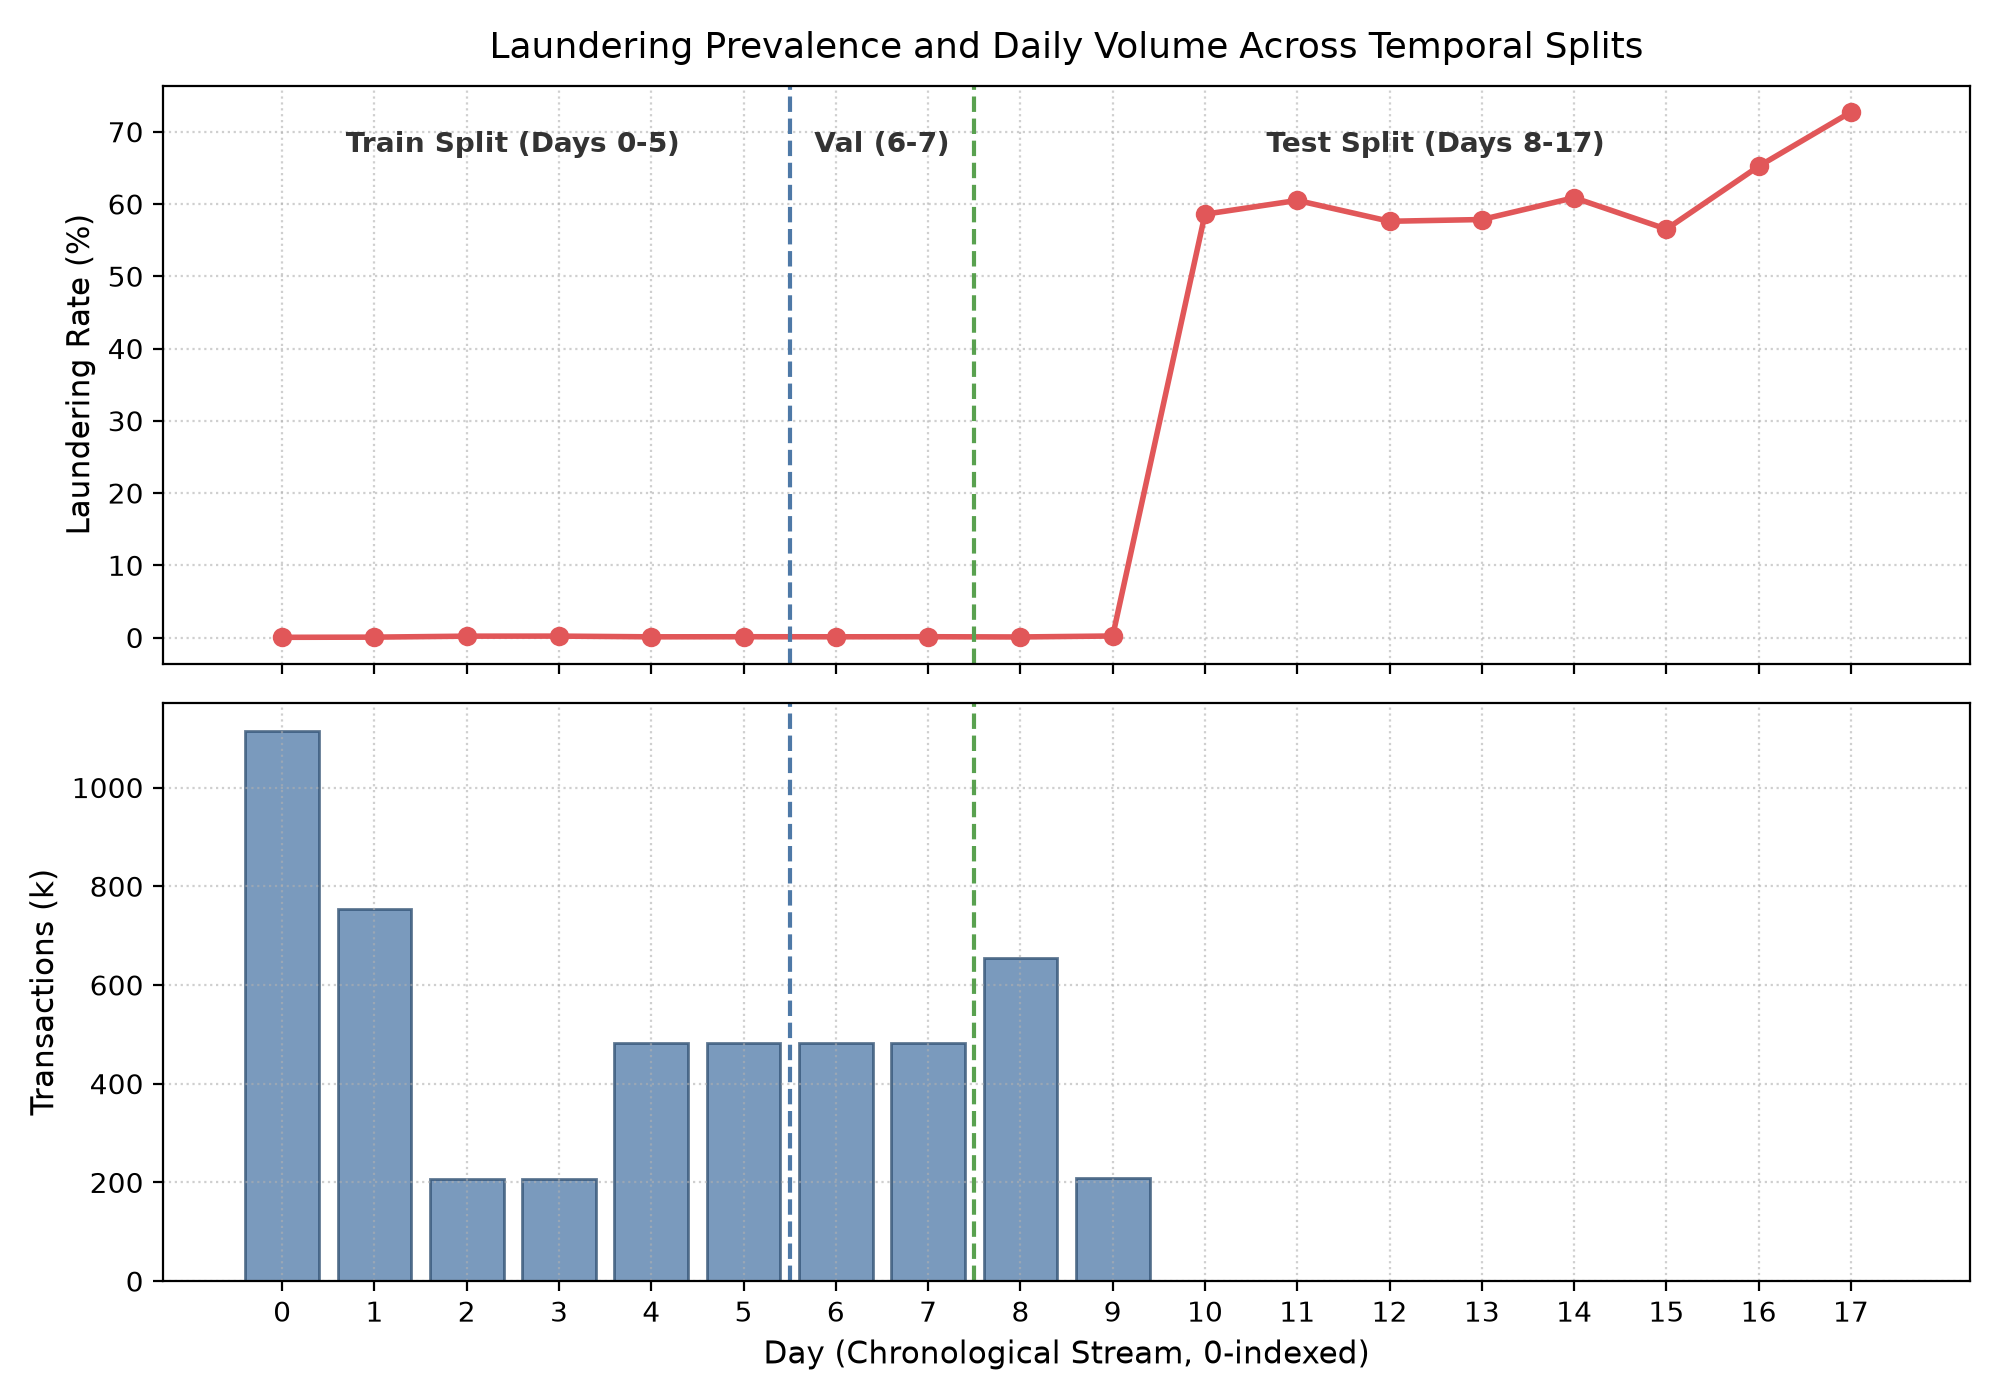

,day,total_transactions,laundering_transactions,laundering_rate_pct
0,0,1114921,322,0.028881
1,1,754449,408,0.054079
2,2,207382,391,0.188541
3,3,207430,407,0.196211
4,4,482650,471,0.097586
5,5,482089,531,0.110146


In [3]:
df_daily = ra.eda_daily_laundering_plot()
display(Image(filename='../results/figures/report_eda_daily_laundering.png'))
display(df_daily.head(6))

## 3. Payment Format and Currency Breakdown

The tables and figure show the distribution across payment formats and the top 8 sent currencies, verifying row counts against `HI-Small_Trans.csv`, and comparing the proportion of all positives versus negatives.

### Payment Format Distribution

,Code,Payment Format,Rows,Laundering Rows,Laundering Rate (%),Share of Positives (%),Share of Negatives (%)
0,1,Cheque,1864331,324,0.0174,6.26,36.74
1,2,Credit Card,1323324,206,0.0156,3.98,26.08
2,3,ACH,600797,4483,0.7462,86.59,11.75
3,4,Cash,490891,108,0.0220,2.09,9.67
4,0,Reinvestment,481056,0,0.0000,0.00,9.48
5,5,Wire,171855,0,0.0000,0.00,3.39
6,6,Bitcoin,146091,56,0.0383,1.08,2.88


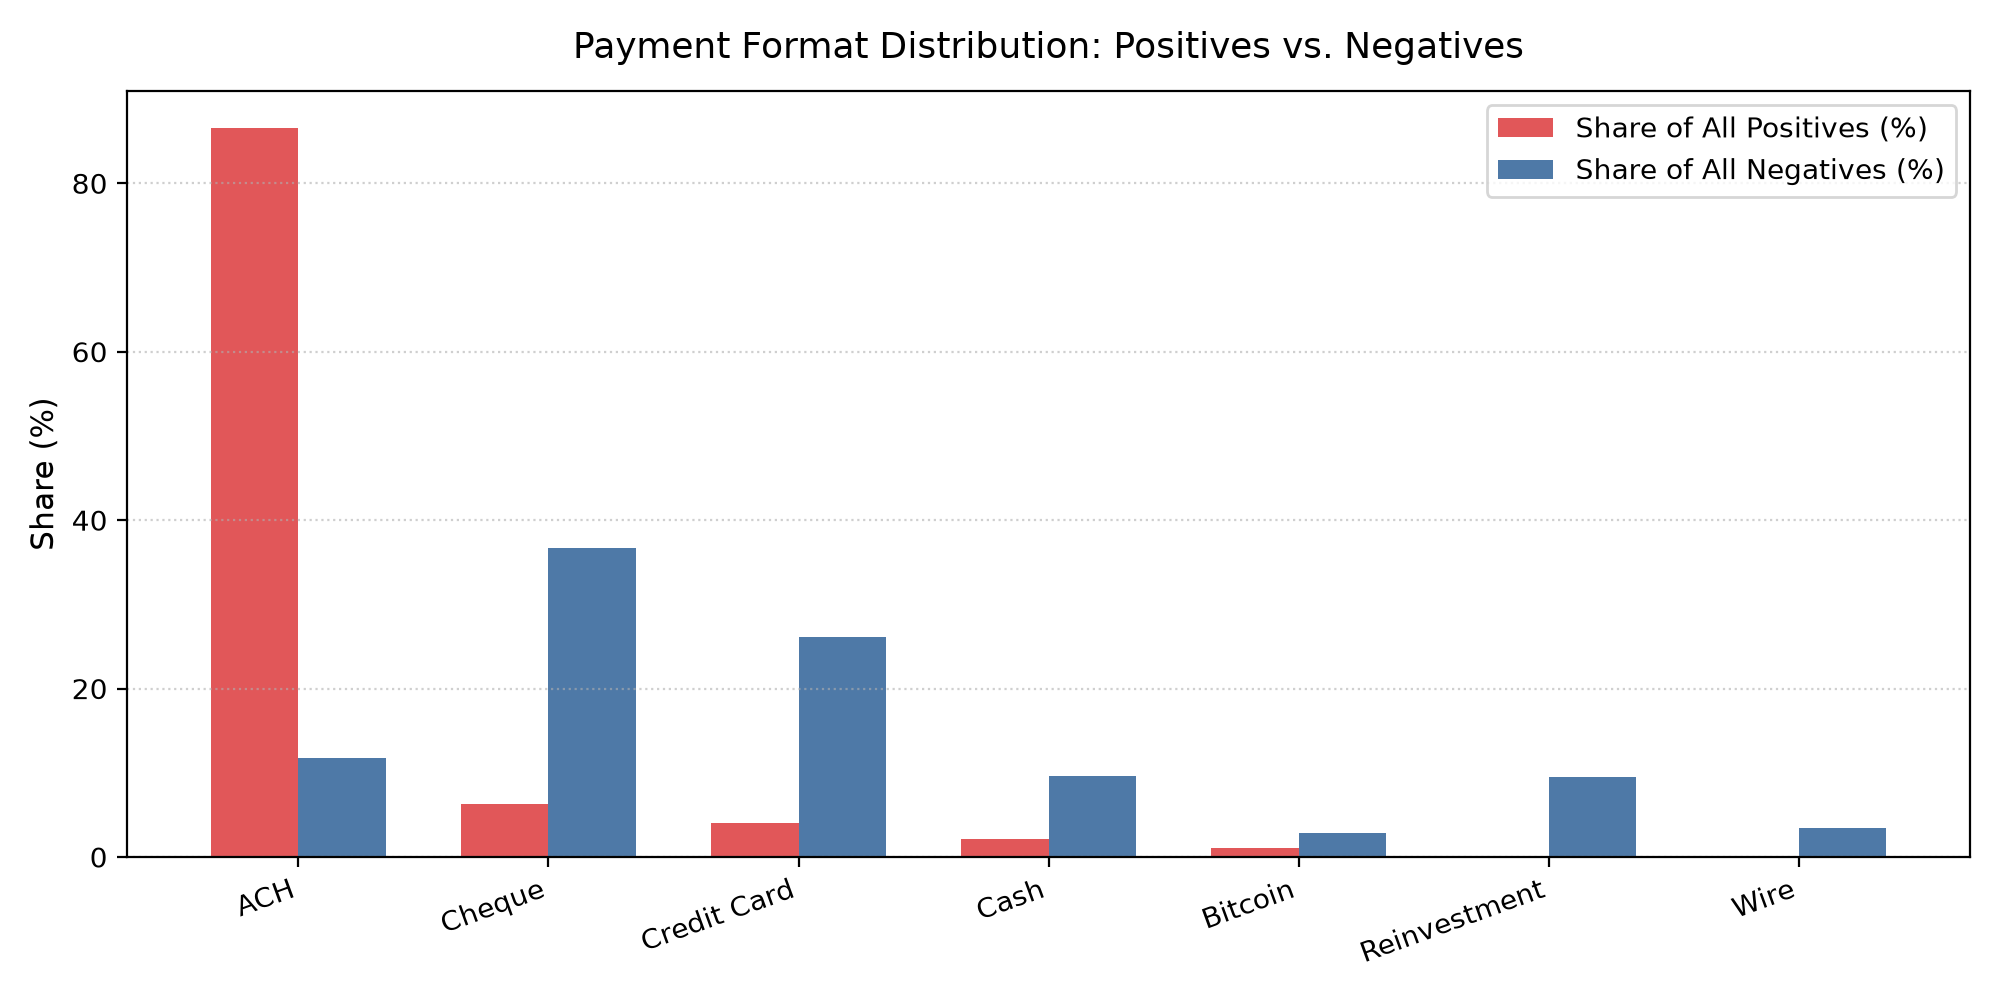

### Top 8 Sent Currencies

,Code,Currency,Rows,Laundering Rows,Laundering Rate (%),Share of Positives (%),Share of Negatives (%)
0,0,US Dollar,1895172,1912,0.1009,36.93,37.32
1,2,Euro,1168297,1372,0.1174,26.50,23.00
2,11,Swiss Franc,234860,193,0.0822,3.73,4.63
3,4,Yuan,213752,184,0.0861,3.55,4.21
4,14,Shekel,192184,95,0.0494,1.84,3.79
5,5,Rupee,190202,167,0.0878,3.23,3.75
6,8,UK Pound,180738,132,0.0730,2.55,3.56
7,6,Yen,155209,155,0.0999,2.99,3.06


In [4]:
df_pf, df_curr = ra.eda_payment_format_table_and_plot()
display(Markdown('### Payment Format Distribution'))
display(df_pf)
display(Image(filename='../results/figures/report_eda_payment_format.png'))
display(Markdown('### Top 8 Sent Currencies'))
display(df_curr)

## 4. Transaction Amounts Distribution

The figure displays density-normalized histograms of log10(Amount Sent) comparing all laundering positives (N=5,177) against a random sample of 200,000 negatives. The table lists the median and 99th percentile amounts.

,Class,Median Amount,99th Percentile Amount,Median log10(Amount),99th Percentile log10(Amount)
0,"Positives (All N=5,177)",8667.21,23420046.84,3.938,7.370
1,"Negatives (Sample N=200,000)",1418.51,13604284.33,3.152,7.134


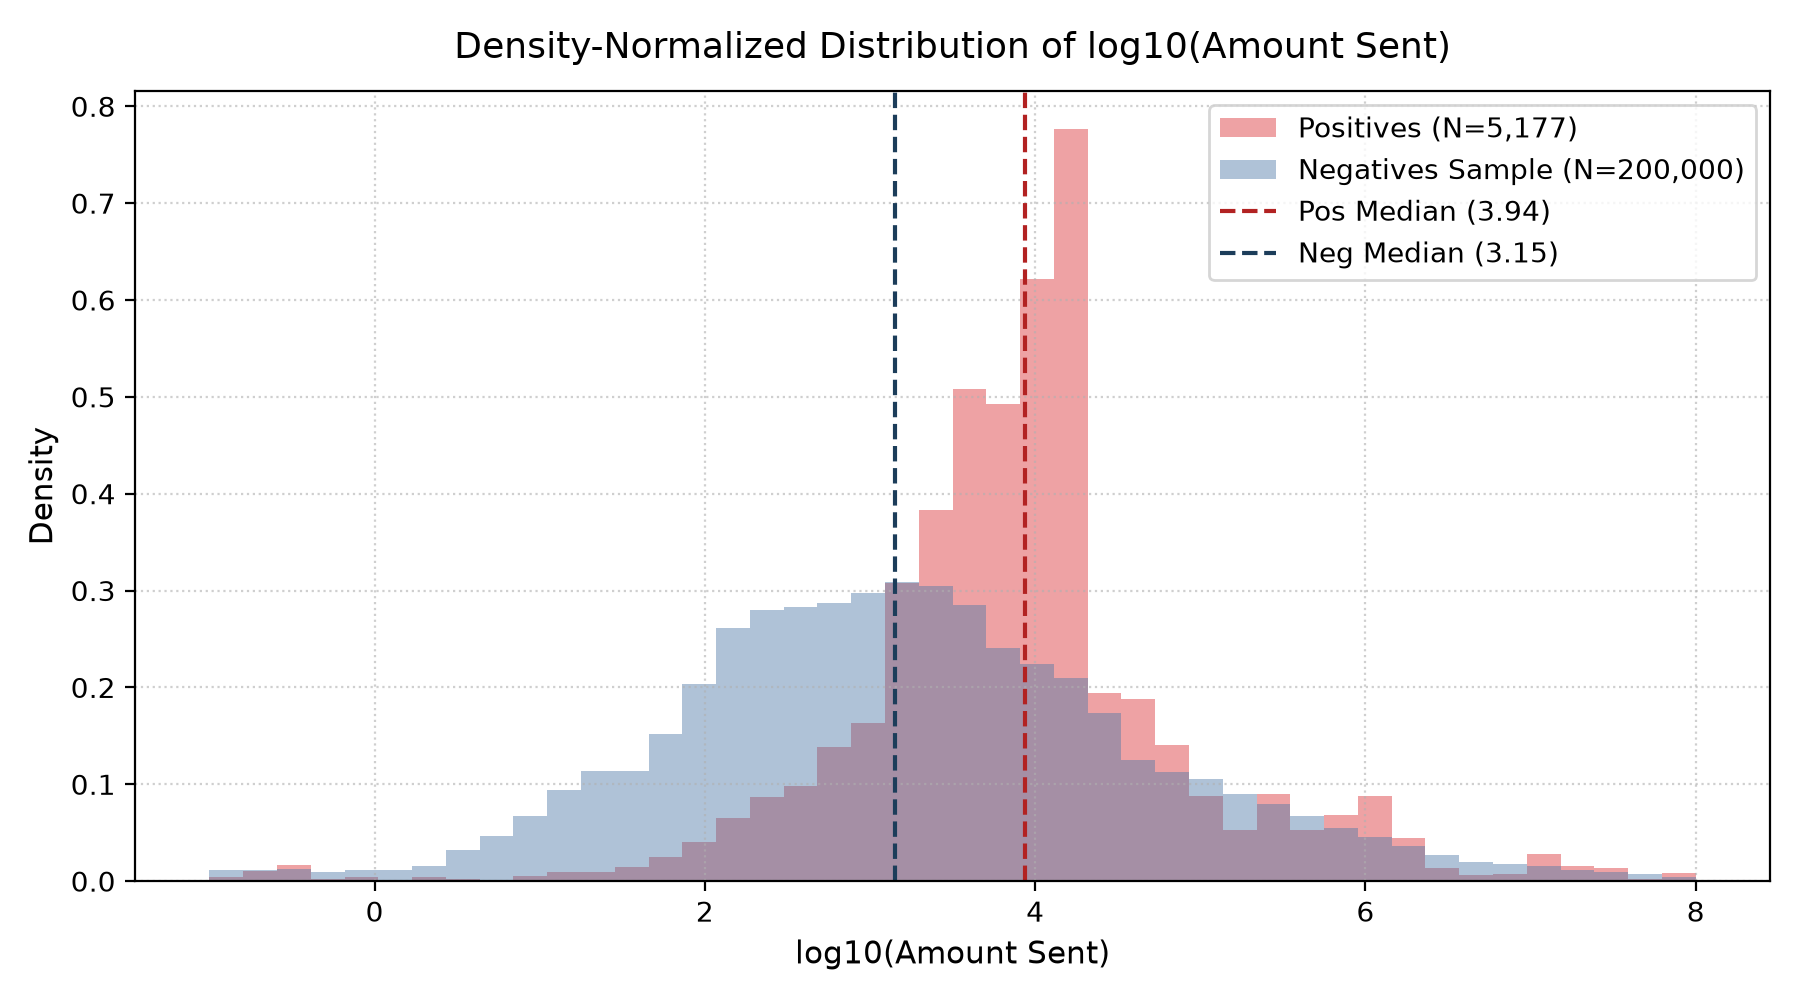

In [5]:
df_amt = ra.eda_amounts_table_and_plot()
display(df_amt)
display(Image(filename='../results/figures/report_eda_amounts.png'))

## 5. Temporal Patterns: Hour of Day and Day of Week

The figure shows laundering rates (%) across the 24 hours of the day (UTC) on the left panel and across days of the week (Monday through Sunday) on the right panel.

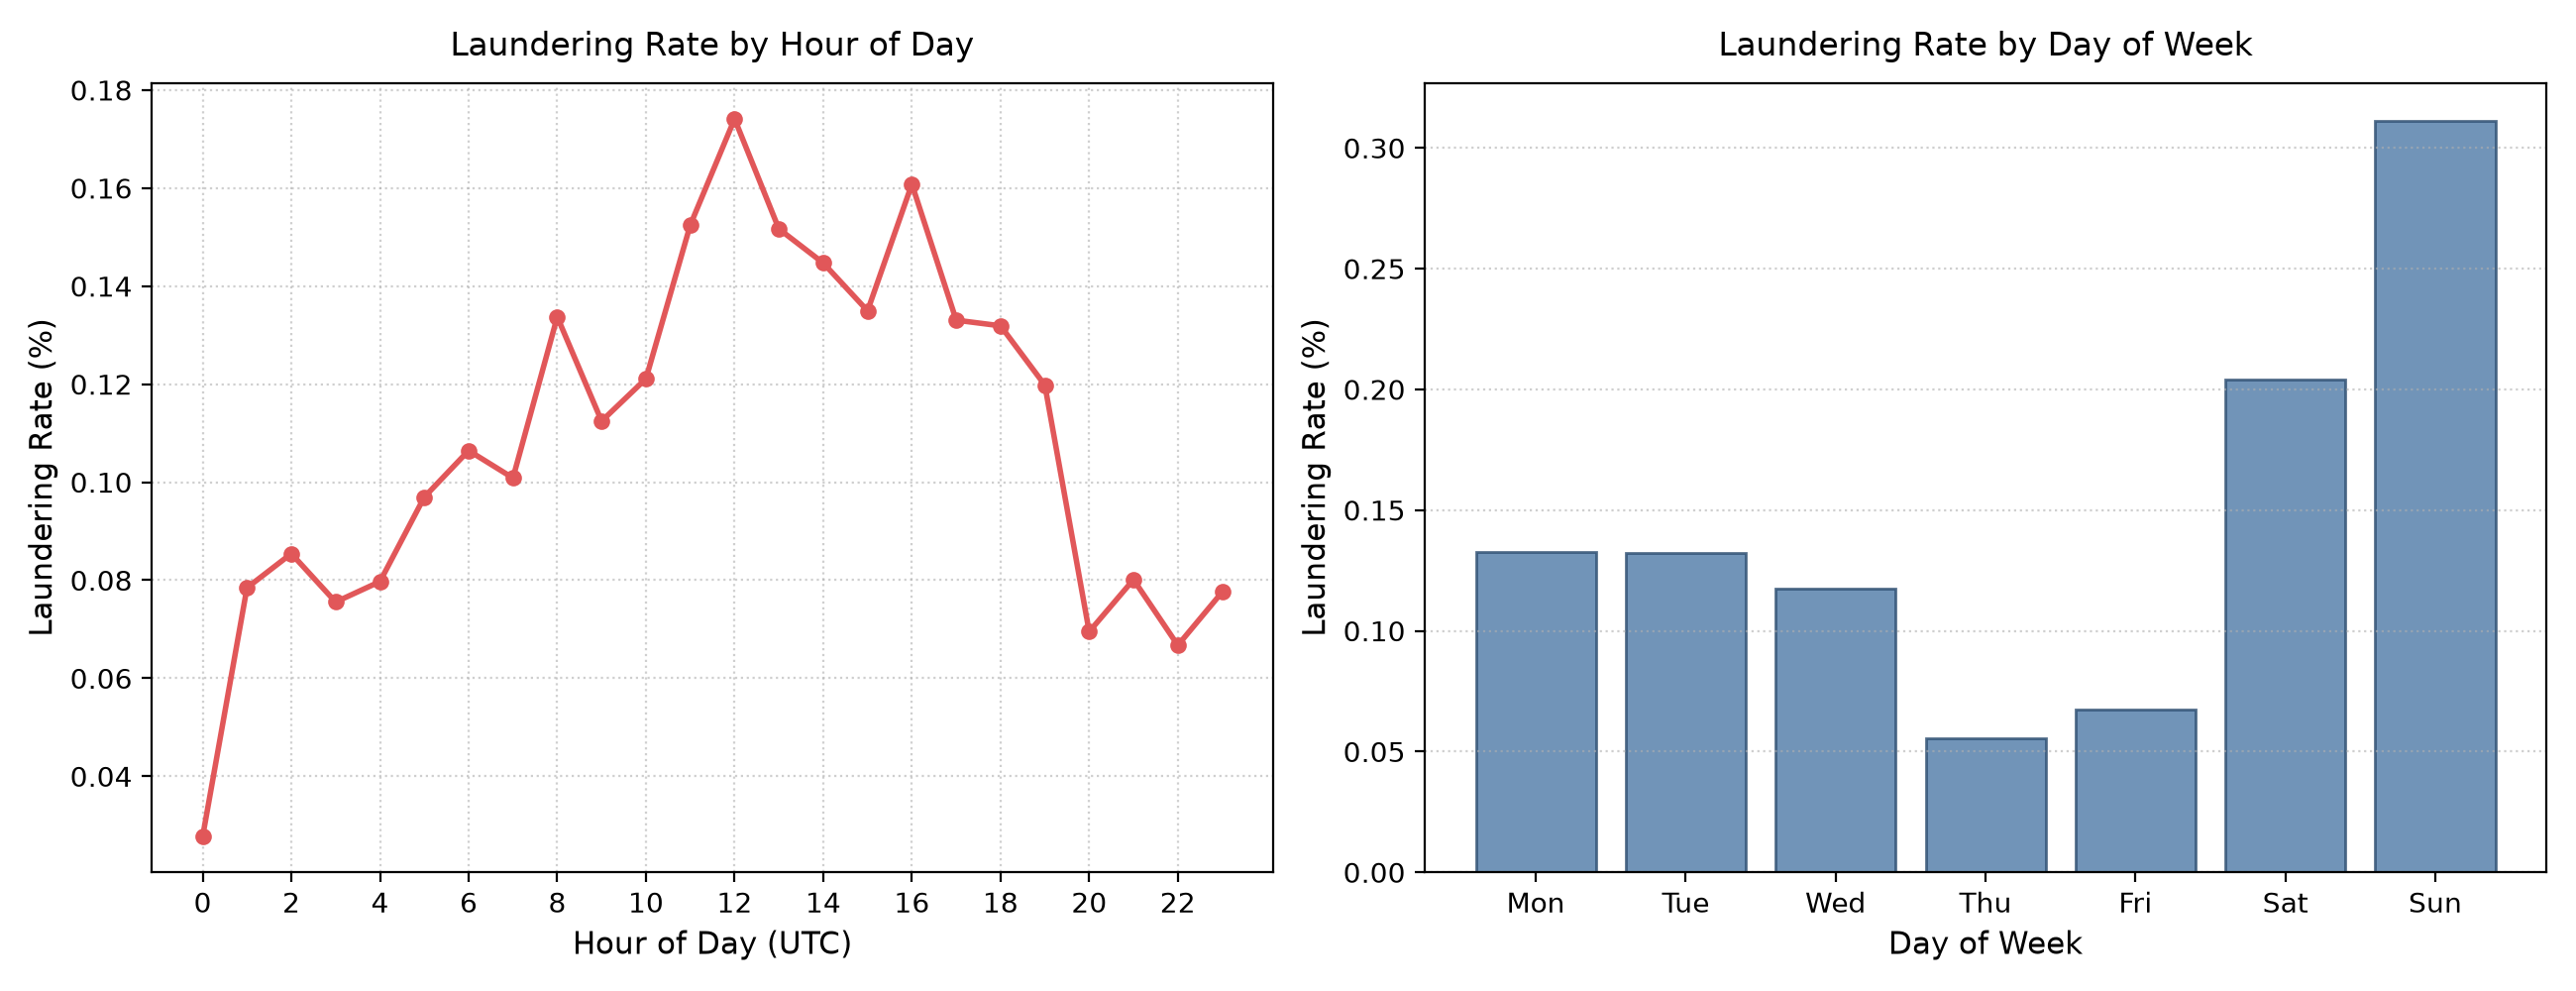

In [6]:
df_h, df_dow = ra.eda_time_patterns_plot()
display(Image(filename='../results/figures/report_eda_hourly_weekly.png'))

## 6. Account History and First-Time Pair Dynamics

The table reports the proportion of transactions with zero prior sender or receiver history across temporal splits. The line plot displays the daily percentage of first-time pair transactions (`pair_prior_cnt == 0`) across the stream.

,Split,Total Rows,No Sender History Rows,No Sender History (%),No Receiver History Rows,No Receiver History (%)
0,Train,3248921,429403,13.22,371811,11.44
1,Validation,965524,901,0.09,219,0.02
2,Test,863900,880,0.10,190,0.02


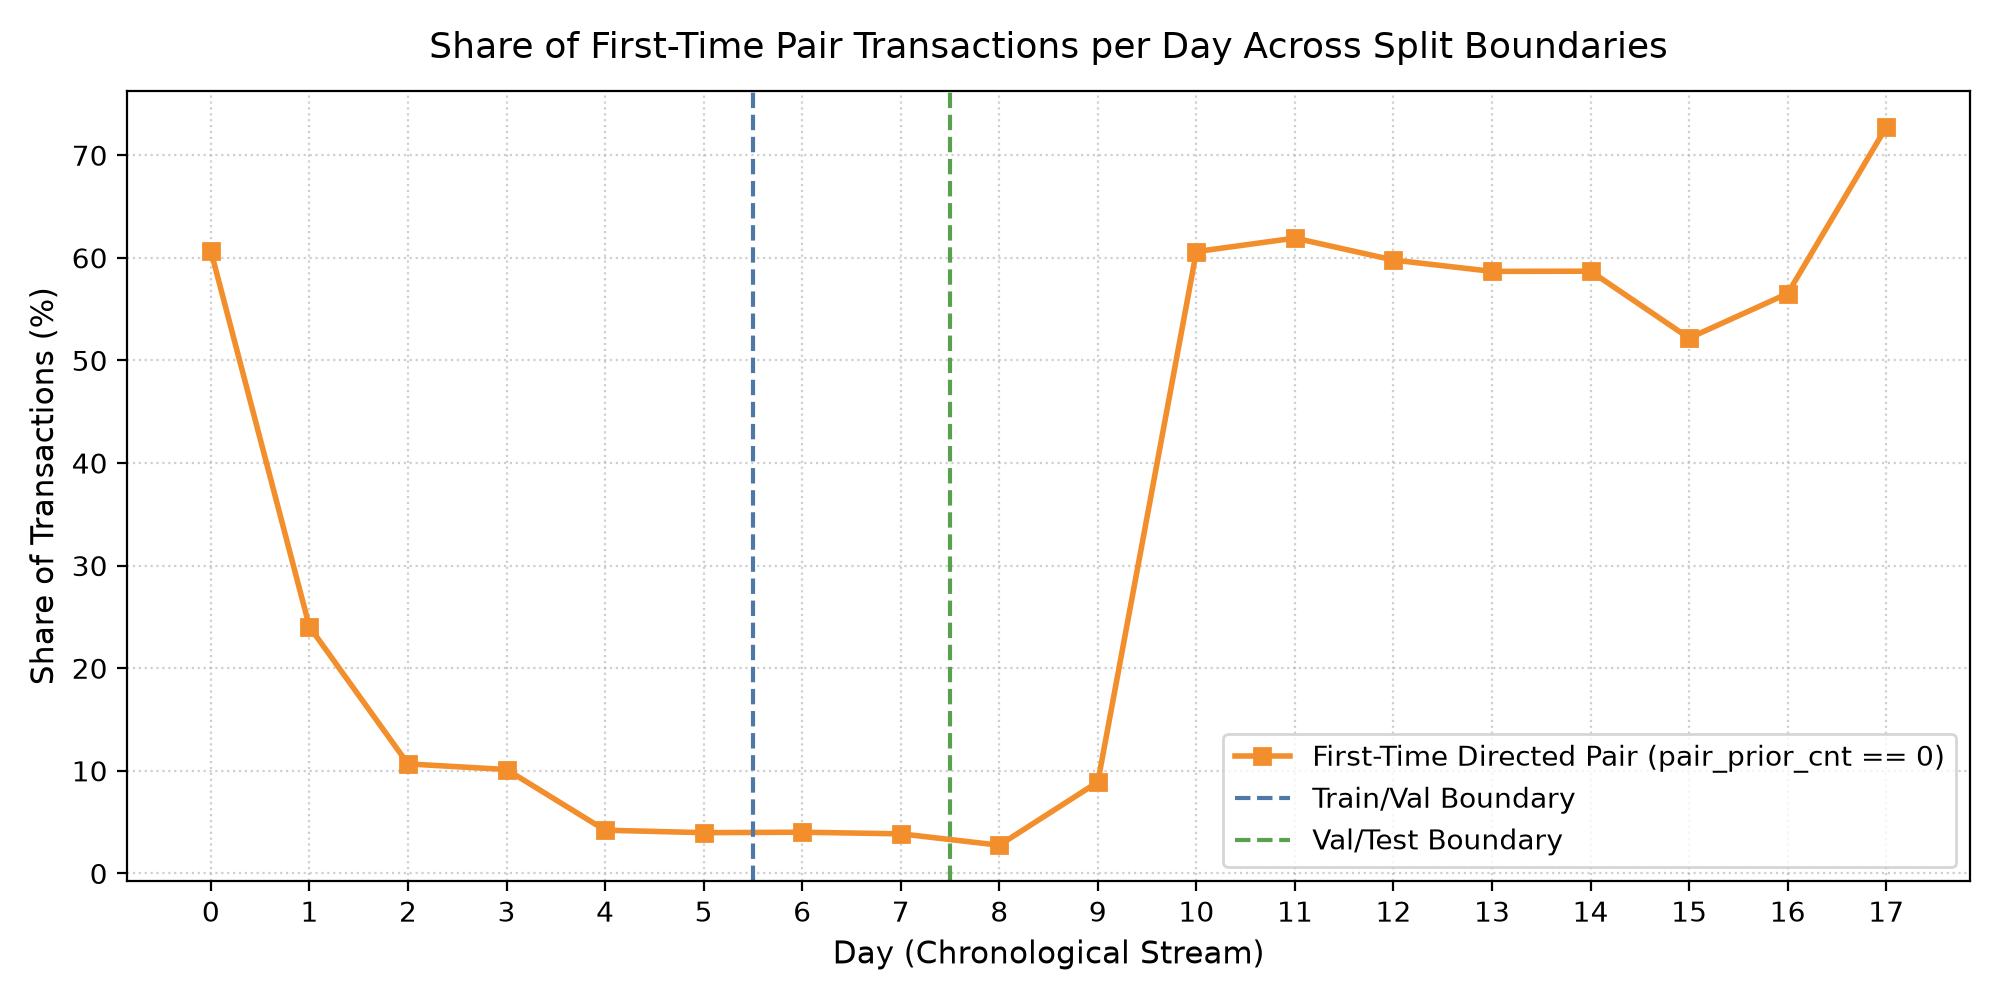

In [7]:
df_cov, df_dp = ra.eda_account_history()
display(df_cov)
display(Image(filename='../results/figures/report_eda_pair_prior_cnt_daily.png'))

## 7. Laundering Rate by Prior Pair History

The table compares laundering rates and enrichment ratios between first-time directed pairings (`pair_prior_cnt == 0`) and recurring pairings (`pair_prior_cnt > 0`) across train, validation, and test splits.

In [8]:
df_pp = ra.eda_pair_prior_laundering_rate()
display(df_pp)

,Split,Condition,Total Rows,Laundering Rows,Laundering Rate (%),Enrichment vs Prior
0,Train,pair_prior_cnt == 0,940490,1955,0.2079,8.35
1,Train,pair_prior_cnt > 0,2308431,575,0.0249,1.00
2,Validation,pair_prior_cnt == 0,38025,764,2.0092,68.51
3,Validation,pair_prior_cnt > 0,927499,272,0.0293,1.00
4,Test,pair_prior_cnt == 0,37221,1276,3.4282,84.60
5,Test,pair_prior_cnt > 0,826679,335,0.0405,1.00
